# Your First Machine Learning Model: Predicting House Prices

## The scenario

You work at a real estate company in California. Agents keep asking the same question:
**"What's a typical home worth in this neighborhood?"**

Right now someone looks it up by hand every time. Your task is to build a model that **learns from past data**
and estimates the value on its own.

## What is machine learning, in one sentence?

We show the computer lots of examples (neighborhood facts **and** their home values), it finds the pattern, and then it
can guess the value for neighborhoods it has never seen.

## The plan
1. Load the data and look at it
2. Explore it with a few charts
3. Choose what goes in (features) and what we want to predict (target)
4. Split the data into a training set and a test set
5. Train our first model
6. Check how good it is
7. Try a second, stronger model
8. Use the model on a new neighborhood

## Step 0: Import the tools

- **pandas** works with tables of data (like a spreadsheet in Python)
- **matplotlib** draws charts
- **scikit-learn** (`sklearn`) holds the machine learning models

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

## Step 1: Load the data

Each row is one **neighborhood** (a census block group) in California. The columns are:

| Column | Meaning |
|---|---|
| `MedInc` | Median household income, in **\\$10,000s** (so 8.3 means \\$83,000) |
| `HouseAge` | Median age of the houses, in years |
| `AveRooms` | Average number of rooms per home |
| `AveBedrms` | Average number of bedrooms per home |
| `Population` | Number of people living in the neighborhood |
| `AveOccup` | Average number of people per home |
| `Latitude`, `Longitude` | Location on the map |
| `MedHouseVal` | **Median home value, in \\$100,000s** (so 4.5 means \\$450,000). **This is what we want to predict.** |

In [2]:
df = pd.read_csv("data/california_housing.csv")
df.head().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.33,41.0,6.98,1.02,322.0,2.56,37.88,-122.23,4.53
1,8.30,21.0,6.24,0.97,2401.0,2.11,37.86,-122.22,3.58
2,7.26,52.0,8.29,1.07,496.0,2.80,37.85,-122.24,3.52
3,5.64,52.0,5.82,1.07,558.0,2.55,37.85,-122.25,3.41
4,3.85,52.0,6.28,1.08,565.0,2.18,37.85,-122.25,3.42


In [3]:
print("Rows (neighborhoods):", len(df))
print("Columns:", len(df.columns))
print("Missing values:", df.isna().sum().sum())

Rows (neighborhoods): 20640
Columns: 9
Missing values: 0


No missing values, so the data is ready to use as-is. That's rare in real projects, but it lets us focus on the modeling.

## Step 2: Explore the data

Before building anything, it's worth getting a feel for the data. Let's ask three questions.

**What do home values look like?**

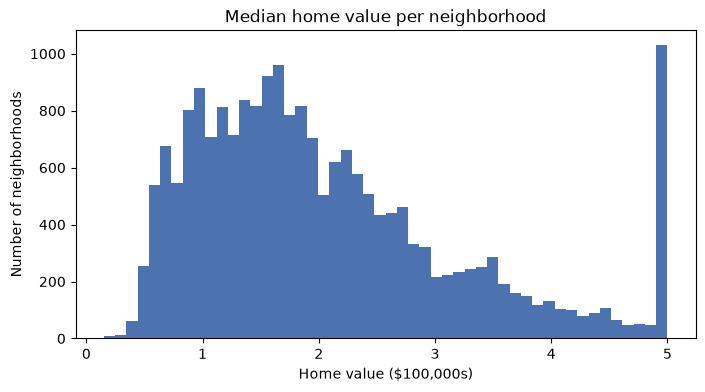

In [4]:
df["MedHouseVal"].plot.hist(bins=50, figsize=(8, 4), color="#4C72B0")
plt.title("Median home value per neighborhood")
plt.xlabel("Home value ($100,000s)")
plt.ylabel("Number of neighborhoods")
plt.show()

Most neighborhoods fall between \\$100k and \\$300k. The tall bar on the far right is a quirk of this dataset: values
above \\$500k were all recorded as exactly \\$500k.

**Does income relate to home value?**

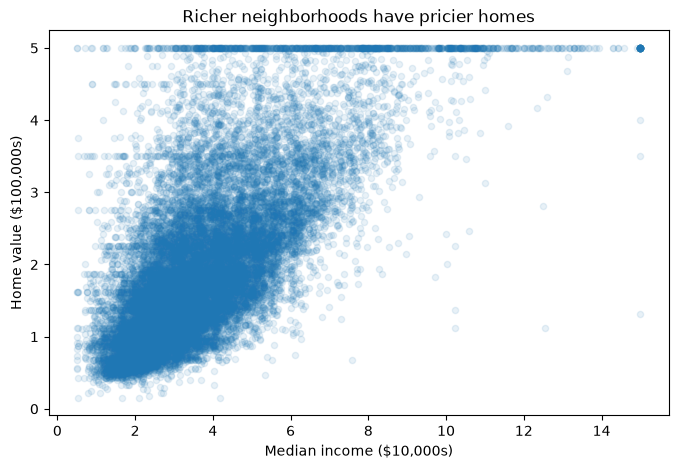

In [5]:
df.plot.scatter(x="MedInc", y="MedHouseVal", alpha=0.1, figsize=(8, 5))
plt.title("Richer neighborhoods have pricier homes")
plt.xlabel("Median income ($10,000s)")
plt.ylabel("Home value ($100,000s)")
plt.show()

There's a clear upward trend: as income goes up, home values go up. That's exactly the kind of pattern a model can learn.

**Does location matter?**

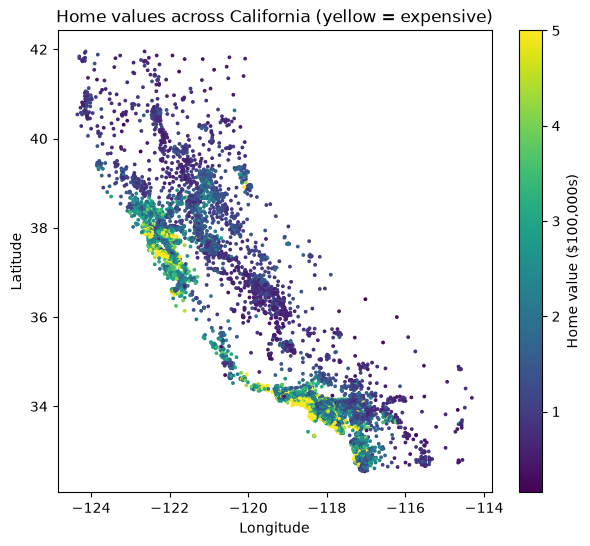

In [6]:
plt.figure(figsize=(7, 6))
plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], cmap="viridis", s=3)
plt.colorbar(label="Home value ($100,000s)")
plt.title("Home values across California (yellow = expensive)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

You can see the shape of California. The expensive (yellow) areas are along the coast: the San Francisco Bay Area
and Los Angeles. So **location** matters too.

## Step 3: Features and target

In machine learning we split the columns into two groups:

- **Features (`X`)**: the information we give the model, everything except the price
- **Target (`y`)**: the answer we want it to predict, the home value

In [7]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("Features:", list(X.columns))

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## Step 4: Split into training and test sets

This is the most important idea in this notebook.

If we test the model on the same data it learned from, it's like giving a student the exam answers to study:
a perfect score tells us nothing. So we **hide 20% of the data** and only use it at the end to check the model.

- **Training set (80%)**: the model learns from these
- **Test set (20%)**: the model never sees these during training; we use them to grade it

`random_state=42` just makes the random split the same every time you run it.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Test rows:    ", len(X_test))

Training rows: 16512
Test rows:     4128


## Step 5: Train our first model

We start with **linear regression**, the simplest model. It finds the best straight-line relationship between the
features and the price, roughly: *price = (some amount × income) + (some amount × house age) + ...*

Every scikit-learn model works the same way:
1. Create it: `model = LinearRegression()`
2. Train it: `model.fit(X_train, y_train)`
3. Predict: `model.predict(X_test)`

In [2]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

NameError: name 'X_train' is not defined

Let's put a few predictions next to the real answers:

In [10]:
comparison = pd.DataFrame({
    "Actual value": y_test.values[:5] * 100_000,
    "Predicted value": linear_predictions[:5] * 100_000,
})
comparison.style.format("${:,.0f}")

,Actual value,Predicted value
0,"$47,700","$71,912"
1,"$45,800","$176,402"
2,"$500,001","$270,966"
3,"$218,600","$283,893"
4,"$278,000","$260,466"


## Step 6: How good is it?

Looking at five rows isn't enough. We'll use two standard scores over the whole test set:

- **Mean Absolute Error (MAE)**: on average, how far off is each prediction? Lower is better. We'll show it in dollars.
- **R² score**: how much of the variation in prices the model explains. 1.0 is perfect, 0 is no better than guessing the average.

To know if a score is good, we need something to compare it to. Our **baseline** is the laziest possible "model":
always guess the average price.

In [11]:
average_price = y_train.mean()
baseline_mae = (y_test - average_price).abs().mean()

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_r2 = r2_score(y_test, linear_predictions)

print(f"Baseline (always guess the average): off by ${baseline_mae * 100_000:,.0f} on average")
print(f"Linear regression:                   off by ${linear_mae * 100_000:,.0f} on average  (R² = {linear_r2:.2f})")

Baseline (always guess the average): off by $90,607 on average
Linear regression:                   off by $53,320 on average  (R² = 0.58)


Linear regression cuts the error by about 40% compared with guessing. That's a real improvement, but
being off by around \\$53k on a typical home is still a lot. Can we do better?

## Step 7: Try a stronger model

A **random forest** builds many **decision trees** and averages their answers. Each tree asks a series of yes/no
questions, like *"Is income above \\$50k? Is it near the coast?"*. That lets it pick up patterns a straight line
can't, such as "coastal homes are expensive, but only in certain areas."

Notice the code is **exactly the same three steps**. Only the model name changes. That consistency is one
of the best things about scikit-learn.

*(This one takes about 10–20 seconds to train.)*

In [12]:
forest_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_r2 = r2_score(y_test, forest_predictions)

results = pd.DataFrame({
    "Average error ($)": [baseline_mae * 100_000, linear_mae * 100_000, forest_mae * 100_000],
    "R² score": [0.0, linear_r2, forest_r2],
}, index=["Baseline (guess average)", "Linear regression", "Random forest"])
results.style.format({"Average error ($)": "${:,.0f}", "R² score": "{:.2f}"})

,Average error ($),R² score
Baseline (guess average),"$90,607",0.00
Linear regression,"$53,320",0.58
Random forest,"$32,784",0.80


The random forest is clearly better: it's off by about \\$33k on average and explains about 80% of the variation in prices.

### Seeing the predictions

If the model were perfect, every dot would sit on the red dashed line (prediction = actual).

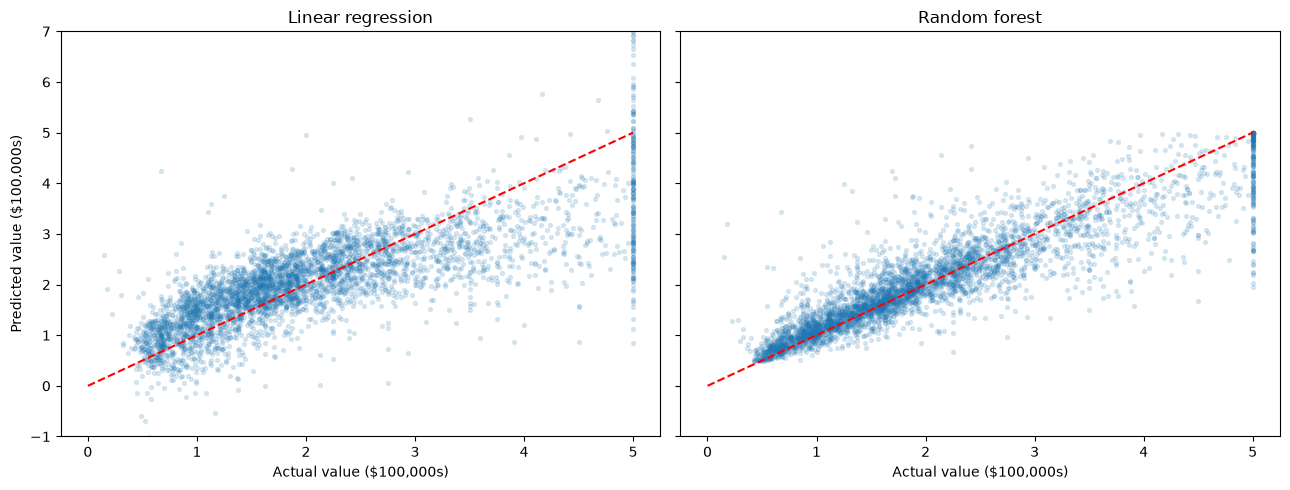

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, preds, title in [(axes[0], linear_predictions, "Linear regression"),
                         (axes[1], forest_predictions, "Random forest")]:
    ax.scatter(y_test, preds, alpha=0.15, s=8)
    ax.plot([0, 5], [0, 5], "r--")
    ax.set_title(title)
    ax.set_xlabel("Actual value ($100,000s)")
    ax.set_ylim(-1, 7)  # zoom in on realistic prices; a few extreme linear predictions fall outside
axes[0].set_ylabel("Predicted value ($100,000s)")
plt.tight_layout()
plt.show()

The random forest's dots hug the line more tightly. The linear model's dots spread out more, and some even go below zero, which is impossible for a price.

### What did the model rely on most?

A random forest can tell us how much each feature helped its predictions.

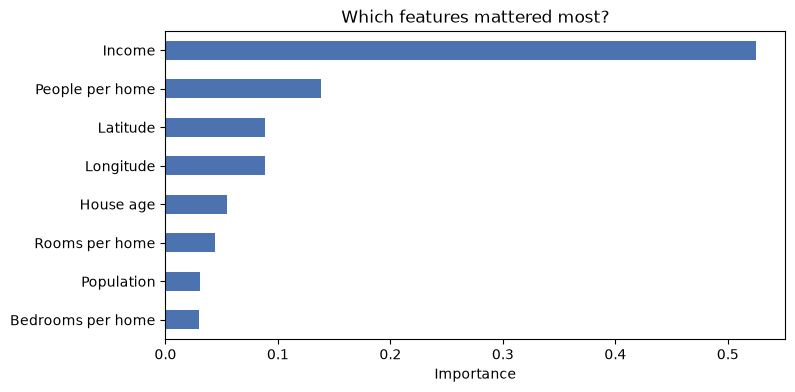

In [14]:
friendly_names = {
    "MedInc": "Income", "HouseAge": "House age", "AveRooms": "Rooms per home",
    "AveBedrms": "Bedrooms per home", "Population": "Population",
    "AveOccup": "People per home", "Latitude": "Latitude", "Longitude": "Longitude",
}
importance = pd.Series(forest_model.feature_importances_, index=X.columns).rename(friendly_names).sort_values()
importance.plot.barh(figsize=(8, 4), color="#4C72B0")
plt.title("Which features mattered most?")
plt.xlabel("Importance")
plt.show()

**Income** is by far the most important, followed by **people per home** and **location** (latitude and longitude). This matches what our charts showed in Step 2.

## Step 8: Use the model on a new neighborhood

An agent asks about a neighborhood that isn't in our data. We describe it with the same 8 features and ask the model.

In [15]:
new_neighborhood = pd.DataFrame([{
    "MedInc": 6.5,        # median income $65,000
    "HouseAge": 20,       # houses about 20 years old
    "AveRooms": 6,
    "AveBedrms": 1,
    "Population": 1200,
    "AveOccup": 3,
    "Latitude": 37.4,     # near San Jose, in the Bay Area
    "Longitude": -121.9,
}])

estimate = forest_model.predict(new_neighborhood)[0]
print(f"Estimated median home value: ${estimate * 100_000:,.0f}")

Estimated median home value: $312,006


Try changing the numbers above, e.g. lower the income or move the latitude and longitude to inland California (around `36.7, -119.8` for Fresno), and run the cell again to see how the estimate changes.

## Recap

You built a complete machine learning workflow:

| Step | What we did | Code |
|---|---|---|
| Load | Read the data into a table | `pd.read_csv(...)` |
| Explore | Charts to find patterns | `df.plot...` |
| Features & target | Inputs (`X`) vs the answer (`y`) | `df.drop(...)` |
| Split | Hide a test set for honest grading | `train_test_split(...)` |
| Train | The model learns the pattern | `model.fit(X_train, y_train)` |
| Predict | Guess values for unseen rows | `model.predict(X_test)` |
| Evaluate | Compare against a baseline | `mean_absolute_error`, `r2_score` |

**Key ideas to remember**
- Always test on data the model **hasn't seen**.
- Always compare against a simple **baseline**.
- In scikit-learn, every model uses the same `fit` / `predict` steps, so trying a new model is one line of change.

**Ideas to try next**
- Swap in another model, like `from sklearn.ensemble import GradientBoostingRegressor`.
- Remove `Latitude` and `Longitude` from `X` and see how much worse the model gets.
- Change `n_estimators` in the random forest (try 10 or 300) and see what happens to accuracy and training time.